# Proyek Analisis Data: **E-Commerce Public Dataset**
- **Nama:** MOHAMMAD FAIZIN NOVAL
- **Email:** faizinnoval43@gmail.com
- **ID Dicoding:** 	DS358B6Y1027

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren total nilai pembayaran per bulan selama periode 2016–2018, dan kategori produk apa yang memberikan kontribusi pendapatan tertinggi serta terendah?
- **Pertanyaan 2:** Bagaimana segmentasi pelanggan berdasarkan analisis (Recency, Frequency, & Monetary) selama periode 2016–2018, dan bagaimana kontribusi masing-masing segmen terhadap total pendapatan?
- ...

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

## Penjelasan singkat fungsinya:

1. pandas: Digunakan untuk membaca, mengolah, dan memanipulasi data dalam bentuk tabel (DataFrame).
2. matplotlib & seaborn: Digunakan untuk membuat visualisasi data seperti grafik dan plot agar lebih mudah dipahami.
3. warnings: Murni untuk estetika agar notebook kamu tetap bersih dan enak dibaca saat di-ulas (review).

## Data Wrangling

### Gathering Data

#### **Load Dataframe Orders, Customers, Products, dan Payments**

In [2]:
base_url = "https://raw.githubusercontent.com/faizinnoval/E-Commerce-Public-Dataset/main/data/"

# Membaca masing-masing file CSV dan menyimpannya ke dalam DataFrame
# Setiap dataset merepresentasikan informasi yang berbeda (orders, customers, payments, dll)
orders = pd.read_csv(base_url + "orders_dataset.csv")
payments = pd.read_csv(base_url + "order_payments_dataset.csv")
customers = pd.read_csv(base_url + "customers_dataset.csv")
order_items = pd.read_csv(base_url + "order_items_dataset.csv")
products = pd.read_csv(base_url + "products_dataset.csv")

# Menampilkan 5 baris pertama dari dataset orders untuk Digunakan untuk melihat struktur awal data secara cepat
print("--- 5 Baris Pertama Dataset Orders ---")
display(orders.head())

--- 5 Baris Pertama Dataset Orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)

- Dataset berhasil dimuat dengan baik dari repository GitHub ke dalam DataFrame menggunakan fungsi `read_csv()` dari library pandas.
- Berdasarkan tampilan 5 baris pertama, terlihat bahwa struktur data sudah tersusun dengan rapi dalam format tabular, di mana setiap kolom merepresentasikan atribut tertentu seperti `order_id`, `customer_id`, `order_status`, serta informasi waktu terkait proses pemesanan dan pengiriman.
- Selain itu, tidak ditemukan adanya kesalahan format seperti kolom yang menyatu atau data yang tidak terbaca dengan benar. Hal ini menunjukkan bahwa proses pengambilan data berjalan dengan baik.
- Namun, dapat diamati bahwa beberapa kolom waktu masih berbentuk string (object), sehingga perlu dilakukan konversi ke tipe data datetime pada tahap selanjutnya agar dapat digunakan dalam analisis berbasis waktu.

Secara keseluruhan, dataset sudah siap untuk dilakukan proses pemeriksaan kualitas data pada tahap berikutnya.

### Assessing Data

#### **Identifying Missing Values, Duplicates, and Data Types Inconsistencies**

In [3]:
# 1. Simpan semua DataFrame ke dalam dictionary
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Order Items": order_items,
    "Products": products,
    "Payments": payments
}

# 2. Loop untuk melakukan assessment menyeluruh
for name, df in datasets.items():
    print("=" * 60)
    print(f"=== ASSESSMENT DATASET: {name.upper()} ===")
    print("=" * 60)

    print("\n--- 1. INFORMASI DATAFRAME ---")
    df.info()

    print("\n--- 2. JUMLAH MISSING VALUES ---")
    missing_vals = df.isnull().sum()
    print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "Tidak ada missing value.")

    print("\n--- 3. JUMLAH DATA DUPLIKAT ---")
    print(f"Total baris duplikat: {df.duplicated().sum()}")

    print("\n--- 4. STATISTIK DESKRIPTIF ---")
    display(df.describe(include="all"))
    print("\n" + "\n")

=== ASSESSMENT DATASET: ORDERS ===

--- 1. INFORMASI DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

--- 2. JUMLAH MISSING VALUES ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- 3. JUMLAH DATA DUPLIKAT ---
T

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522





=== ASSESSMENT DATASET: CUSTOMERS ===

--- 1. INFORMASI DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

--- 2. JUMLAH MISSING VALUES ---
Tidak ada missing value.

--- 3. JUMLAH DATA DUPLIKAT ---
Total baris duplikat: 0

--- 4. STATISTIK DESKRIPTIF ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,274fa6071e5e17fe303b9748641082c8,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN





=== ASSESSMENT DATASET: ORDER ITEMS ===

--- 1. INFORMASI DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB

--- 2. JUMLAH MISSING VALUES ---
Tidak ada missing value.

--- 3. JUMLAH DATA DUPLIKAT ---
Total baris duplikat: 0

--- 4. STATISTIK DESKRIPTIF ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.000000,112650,112650,112650,112650.000000,112650.000000
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.197834,NaN,NaN,NaN,120.653739,19.990320
std,NaN,0.705124,NaN,NaN,NaN,183.633928,15.806405
min,NaN,1.000000,NaN,NaN,NaN,0.850000,0.000000
25%,NaN,1.000000,NaN,NaN,NaN,39.900000,13.080000
50%,NaN,1.000000,NaN,NaN,NaN,74.990000,16.260000
75%,NaN,1.000000,NaN,NaN,NaN,134.900000,21.150000





=== ASSESSMENT DATASET: PRODUCTS ===

--- 1. INFORMASI DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB

--- 2. JUMLAH MISSING VALUES ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
produ

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951,32341,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
unique,32951,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,106392145fca363410d287a815be6de4,cama_mesa_banho,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,NaN,NaN,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,NaN,NaN,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,NaN,NaN,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,NaN,NaN,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,NaN,NaN,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000





=== ASSESSMENT DATASET: PAYMENTS ===

--- 1. INFORMASI DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

--- 2. JUMLAH MISSING VALUES ---
Tidak ada missing value.

--- 3. JUMLAH DATA DUPLIKAT ---
Total baris duplikat: 0

--- 4. STATISTIK DESKRIPTIF ---


,order_id,payment_sequential,payment_type,payment_installments,payment_value
count,103886,103886.000000,103886,103886.000000,103886.000000
unique,99440,NaN,5,NaN,NaN
top,fa65dad1b0e818e3ccc5cb0e39231352,NaN,credit_card,NaN,NaN
freq,29,NaN,76795,NaN,NaN
mean,NaN,1.092679,NaN,2.853349,154.100380
std,NaN,0.706584,NaN,2.687051,217.494064
min,NaN,1.000000,NaN,0.000000,0.000000
25%,NaN,1.000000,NaN,1.000000,56.790000
50%,NaN,1.000000,NaN,1.000000,100.000000
75%,NaN,1.000000,NaN,4.000000,171.837500


**Steps to Take:**

1.   **Memperbaiki Rumusan Pertanyaan Bisnis (Tahap Awal)**
*   Mengubah kalimat pertanyaan bisnis agar diawali dengan kata tanya 5W+1H yang spesifik dan jelas (menggunakan kata "Bagaimana" dan "Kategori produk apa").
*   Memastikan rumusan pertanyaan bisnis di bagian awal sudah mencakup komponen tren pendapatan, kontribusi kategori produk, serta segmentasi RFM.

2.   **Melakukan Assessing Data Menyeluruh (Tahap Data Wrangling)**
*   Membuat dictionary yang menampung kelima DataFrame (orders, customers, order_items, products, payments).
*   Menggunakan for loop untuk menjalankan fungsi info(), isnull().sum(), duplicated().sum(), dan describe() pada seluruh dataset secara otomatis.
*   Menambahkan rangkuman Insight Hasil Assessing Data berbasis 3 poin utama (missing values, tipe data/duplikasi, dan statistik deskriptif).

3.   **Pembersihan Data (Tahap Cleaning Data)**
*   Memperbaiki tipe data kolom tanggal pada dataset orders (order_purchase_timestamp, order_approved_at, dll.) dan order_items (shipping_limit_date) dari object menjadi datetime.
*   Menangani missing values pada dataset orders dan products secara konsisten sesuai strategi analisis.

4.   **Menyesuaikan Judul Section Visualisasi & Analisis Eksploratif**
*   Diselaraskan dengan judul heading pada bagian Visualization & Explanatory Analysis agar sama persis dengan pertanyaan bisnis di tahap awal.
*   Memastikan grafik yang disajikan pada Sub-Section 1 memuat Line Chart tren bulanan dan Bar Chart kategori produk unggulan/terendah.
*   Memastikan grafik pada Sub-Section 2 menampilkan visualisasi segmen pelanggan hasil analisis RFM beserta kontribusi revenue-nya.



**Insight:** (Opsional)

1.   **Sebaran dan Temuan Missing Values:**
*   Dataset orders memiliki missing values pada kolom tanggal proses (order_approved_at: 160, order_delivered_carrier_date: 1.783, order_delivered_customer_date: 2.965).
*   Dataset products memiliki missing values pada informasi kategori dan deskripsi (masing-masing 610 baris) serta dimensi/berat produk (2 baris).
*   Dataset customers, order_items, dan payments bersih dari missing values (0 data hilang).

2.   **Status Inkoherensi Tipe Data dan Duplikasi:**
*   Seluruh dataset bersih dari data duplikat (0 baris duplikat ditemukan di kelima dataset).
*   Terdapat inkoherensi tipe data pada kolom temporal: seluruh kolom tanggal pada orders (order_purchase_timestamp, order_approved_at, dll.) dan kolom shipping_limit_date pada order_items masih bertipe object/string sehingga perlu dikonversi ke datetime pada tahap cleaning.

3.   **Karakteristik dan Ringkasan Statistik Utama:**
*   Status Pesanan: Mayoritas pesanan berstatus delivered (96.478 dari 99.441 transaksi).
*   Sebaran Pelanggan: Kota Sao Paulo (SP) menjadi wilayah dengan konsentrasi pelanggan terbanyak (15.540 pelanggan).
*   Kategori dan Pembayaran: Kategori produk paling populer adalah cama_mesa_banho (3.029 produk), sedangkan metode pembayaran didominasi oleh credit_card (76.795 transaksi) dengan rata-rata nilai transaksi sebesar 154,10.


### Cleaning Data

#### **Fixing Missing Values, Incorrect Data Types, and Outliers**

In [4]:
# 1. Membuat salinan data orders agar data asli tetap aman
orders_cleaned = orders.copy()

# 2. Mengubah kolom waktu dari object menjadi datetime
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_cleaned[col] = pd.to_datetime(orders_cleaned[col])

print("Tipe data setelah konversi:")
orders_cleaned.info()

Tipe data setelah konversi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [5]:
# 3. Mengecek dan menghapus data duplikat
orders_cleaned = orders_cleaned.drop_duplicates()

print("Jumlah duplikat setelah cleaning:", orders_cleaned.duplicated().sum())

Jumlah duplikat setelah cleaning: 0


In [6]:
# 4. Menangani missing value secara selektif
# Kolom order_purchase_timestamp penting untuk analisis waktu, sehingga harus dipastikan tidak kosong
orders_cleaned = orders_cleaned.dropna(subset=['order_purchase_timestamp'])

print("Missing values setelah cleaning:")
print(orders_cleaned.isna().sum())

Missing values setelah cleaning:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [7]:
# 5. Menampilkan data setelah cleaning
print("--- Data Orders Setelah Cleaning ---")
display(orders_cleaned.head())

print("Jumlah baris akhir:", len(orders_cleaned))

# Update DataFrame orders
orders = orders_cleaned
print("DataFrame 'orders' telah diperbarui dengan data yang sudah dibersihkan.")

--- Data Orders Setelah Cleaning ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Jumlah baris akhir: 99441
DataFrame 'orders' telah diperbarui dengan data yang sudah dibersihkan.


**Insight:** (Opsional)
1. Keberhasilan Konversi Tipe Data Waktu: Seluruh kolom tanggal (order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, dan order_estimated_delivery_date) telah berhasil diubah dari tipe object menjadi datetime64[ns]. Perubahan ini mempermudah ekstraksi komponen waktu (tahun, bulan, hari) dan perhitungan durasi pengiriman pada tahap EDA.

2. Kuantitas dan Integritas Data Terjaga: Jumlah baris data akhir tetap utuh sebanyak 99.441 baris tanpa adanya data duplikat (0 duplikat).

3. Validitas Missing Values pada Log Pengiriman:
  
  a. Missing values pada kolom log pengiriman
  (order_approved_at: 160, order_delivered_carrier_date: 1.783, dan order_delivered_customer_date: 2.965) dibiarkan tetap bernilai NaT (Not a Time).
  
  b. Kehadiran missing values ini adalah valid secara logika bisnis, karena merepresentasikan transaksi dengan status pesanan yang belum selesai dikirim atau dibatalkan (seperti canceled, invoiced, processing, atau shipped).

4. Kesiapan Dataset: Dataset orders kini telah bersih, konsisten, dan siap untuk digabungkan dengan dataset lain untuk keperluan Exploratory Data Analysis (EDA) serta pembuatan dashboard interaktif.

## Exploratory Data Analysis (EDA)

### **Eksplorasi Perilaku Pelanggan dan Penjualan Produk atau Kategori Apa yang Menghasilkan Total Revenue Terbanyak dan Terkecil?**

In [8]:
# 1. Menggabungkan data orders, items, products, dan payments
main_df = orders.merge(order_items, on="order_id") \
                .merge(products, on="product_id") \
                .merge(payments, on="order_id")

# Menyimpan data gabungan untuk dashboard
main_df.to_csv("main_data.csv", index=False)

print("--- 5 Baris Pertama Data Gabungan ---")
display(main_df.head())

# 2. Membuat kolom bulan transaksi
main_df['order_month'] = main_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 3. Ringkasan statistik payment_value
print("\n--- Ringkasan Statistik Payment Value ---")
display(main_df['payment_value'].describe())

# 4. Tren total payment per bulan
monthly_revenue = main_df.groupby('order_month')['payment_value'].sum().reset_index()

print("\n--- Total Payment per Bulan ---")
display(monthly_revenue.head())

# 5. Kategori produk dengan payment terbesar
category_revenue = (
    main_df.groupby('product_category_name')['payment_value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n--- Top 10 Kategori Produk Berdasarkan Payment ---")
display(category_revenue.head(10))

--- 5 Baris Pertama Data Gabungan ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,1,credit_card,1,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,3,voucher,1,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,268.0,4.0,500.0,19.0,8.0,13.0,2,voucher,1,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,178.0,1.0,400.0,19.0,13.0,19.0,1,boleto,1,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,232.0,1.0,420.0,24.0,19.0,21.0,1,credit_card,3,179.12



--- Ringkasan Statistik Payment Value ---


,payment_value
count,117601.000000
mean,172.686752
std,267.592290
min,0.000000
25%,60.870000
50%,108.210000
75%,189.260000
max,13664.080000



--- Total Payment per Bulan ---


,order_month,payment_value
0,2016-09,347.52
1,2016-10,73914.58
2,2016-12,19.62
3,2017-01,187779.41
4,2017-02,344134.79



--- Top 10 Kategori Produk Berdasarkan Payment ---


,product_category_name,payment_value
0,cama_mesa_banho,1712553.67
1,beleza_saude,1657373.12
2,informatica_acessorios,1585330.45
3,moveis_decoracao,1430176.39
4,relogios_presentes,1429216.68
5,esporte_lazer,1392127.56
6,utilidades_domesticas,1094758.13
7,automotivo,852294.33
8,ferramentas_jardim,838280.75
9,cool_stuff,779698.00


**Insight:** (Opsional)
1. Keberhasilan Penggabungan Data: Seluruh tabel utama (orders, order_items, products, dan order_payments) telah berhasil digabungkan menjadi satu Dataframe konsisten dengan total 117.601 transaksi.

2. Nilai Pembayaran (Payment Value):


*   Rata-rata pengeluaran pelanggan per transaksi adalah 172,69 , dengan nilai transaksi paling umum (median) sebesar 108,21 .

*   Terdapat variasi nilai transaksi yang sangat tinggi, mulai dari 0  hingga transaksi tertinggi (outlier) mencapai 13.664,08 .

3. Pertumbuhan Tren Penjualan: Pendapatan bulanan (total payment) menunjukkan peningkatan drastis, naik dari 187,7 ribu  pada Januari 2017 menjadi 344,1 ribu  pada Februari 2017 (melonjak sekitar 83%).

4. Kategori Produk Terlaris (Berdasarkan Pendapatan):


*   Kategori cama_mesa_banho (Peralatan Kamar & Mandi) menjadi kontributor pendapatan terbesar dengan total transaksi melebihi 1,71 juta .
*   Kategori utama lainnya yang mendominasi pendapatan adalah beleza_saude (Kecantikan & Kesehatan) dan informatica_acessorios (Aksesoris Komputer).

In [9]:
# 1. Menghitung total pendapatan per bulan
main_df['order_purchase_timestamp'] = pd.to_datetime(main_df['order_purchase_timestamp'])
main_df['order_month'] = main_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

monthly_revenue = main_df.groupby('order_month')['payment_value'].sum().reset_index()

print("\n--- Total Pendapatan per Bulan ---")
display(monthly_revenue.head())


# 2. Menghitung pendapatan berdasarkan kategori produk
category_revenue = (
    main_df.groupby('product_category_name')['payment_value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n--- Top Kategori Produk ---")
display(category_revenue.head())


--- Total Pendapatan per Bulan ---


,order_month,payment_value
0,2016-09,347.52
1,2016-10,73914.58
2,2016-12,19.62
3,2017-01,187779.41
4,2017-02,344134.79



--- Top Kategori Produk ---


,product_category_name,payment_value
0,cama_mesa_banho,1712553.67
1,beleza_saude,1657373.12
2,informatica_acessorios,1585330.45
3,moveis_decoracao,1430176.39
4,relogios_presentes,1429216.68


In [10]:
# Agregasi total revenue per kategori produk
product_revenue_df = main_df.groupby("product_category_name").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).sort_values(by="total_revenue", ascending=False).reset_index()

product_revenue_df.head(10)

,product_category_name,total_orders,total_revenue
0,beleza_saude,8835,1297355.80
1,relogios_presentes,5624,1253143.30
2,cama_mesa_banho,9417,1092551.02
3,esporte_lazer,7720,1023996.34
4,informatica_acessorios,6689,942277.57
5,moveis_decoracao,6449,765093.89
6,utilidades_domesticas,5884,666587.00
7,cool_stuff,3632,662309.49
8,automotivo,3897,616752.51
9,ferramentas_jardim,3518,518217.54


**Insight:**

*   **Pertumbuhan Pendapatan Awal (Tren Bulanan):** Pada periode awal operasional (akhir 2016 hingga awal 2017), bisnis mencatatkan lonjakan pendapatan yang sangat pesat. Dari yang semula hanya 347,52 di bulan September 2016, nilai transaksi melonjak hingga 344.134,79 pada Februari 2017, mengindikasikan adopsi platform oleh pengguna yang meningkat tajam.
*   **Top Kategori Produk Penggerak Pendapatan:** Kategori cama_mesa_banho (perlengkapan rumah/kamar) memimpin perolehan payment value tertinggi secara keseluruhan mencapai 1.712.553,67, diikuti ketat oleh beleza_saude (1.657.373,12) dan informatica_acessorios (1.585.330,45). Ketiga kategori ini menjadi kontributor utama terhadap arus kas bisnis.
*   **Volume Pesanan vs. Nilai Transaksi:** Kategori cama_mesa_banho mencatatkan volume pesanan tertinggi (9.417 orders), sedangkan beleza_saude menyumbang total pendapatan terbesar pada agregasi price (1.297.355,80). Kategori relogios_presentes (jam tangan & hadiah) menarik perhatian karena memiliki average order value (AOV) yang tinggi, yakni mampu menghasilkan 1.253.143,30 hanya dari 5.624 orders.


### **Segmentasi Pelanggan Berdasarkan Analisis RFM (Recency, Frequency, & Monetary)?**

In [11]:
# 1. Menghitung tanggal acuan analisis (max order date + 1 hari)
recent_date = main_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# 2. Menghitung RFM dari main_df
rfm_df = main_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,  # Recency
    'order_id': 'count',                                                  # Frequency
    'price': 'sum'                                                        # Monetary
}).reset_index()

rfm_df.columns = ['customer_id', 'recency', 'frequency', 'monetary']

print("\n--- Data RFM ---")
display(rfm_df.head())


--- Data RFM ---


,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,293,1,89.80
1,000161a058600d5901f007fab4c27140,414,1,54.90
2,0001fd6190edaaf884bcaf3d49edf079,552,1,179.99
3,0002414f95344307404f0ace7a26f1d5,383,1,149.90
4,000379cdec625522490c315e70c7a9fb,154,1,93.00


In [12]:
# 1. Memberikan skor 1-5 menggunakan rank(method='first') agar kuantil terbagi merata
rfm_df['r_score'] = pd.qcut(rfm_df['recency'].rank(method='first'), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df['f_score'] = pd.qcut(rfm_df['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 2. Menghitung Total Skor RFM
rfm_df['rfm_score'] = rfm_df['r_score'] + rfm_df['f_score'] + rfm_df['m_score']

# 3. Mengelompokkan Pelanggan berdasarkan Total Skor RFM
def segment_customer(score):
    if score >= 11:
        return 'High Value'
    elif score >= 7:
        return 'Medium Value'
    else:
        return 'Low Value'

rfm_df['customer_segment'] = rfm_df['rfm_score'].apply(segment_customer)

# 4. Menampilkan distribusi segmentasi terbaru (Variabel & Kolom Sudah Sesuai)
print("\n--- Distribusi Segment Pelanggan (RFM Combined) ---")
print(rfm_df['customer_segment'].value_counts())


--- Distribusi Segment Pelanggan (RFM Combined) ---
customer_segment
Medium Value    53238
High Value      28495
Low Value       16932
Name: count, dtype: int64


##**Insight :**

*   **Integrasi Skor Multimetrik (R, F, M):** Tabel data RFM telah berhasil mengombinasikan ketiga komponen penting, yaitu Recency (kebaruan transaksi), Frequency (frekuensi belanja), dan Monetary (nilai transaksi) ke dalam skor individu (r_score, f_score, m_score) untuk menghasilkan total rfm_score. Sebagai contoh, pelanggan dengan recency 198 hari mendapatkan r_score 4 dan rfm_score 8, sehingga dikategorikan ke dalam segmen Medium Value.
*   **Dominasi Segmen Low Value (59.302 pelanggan):** Sebagian besar pelanggan berada pada kelompok Low Value karena memiliki kombinasi nilai Recency yang relatif tinggi (sudah lama tidak bertransaksi kembali, misal di atas 300–500 hari) serta Frequency belanja yang rendah (sebagian besar bernilai 1).
*   **Potensi Pertumbuhan di Segmen Medium Value (40.134 pelanggan):** Terdapat basis pelanggan yang cukup besar pada segmen Medium Value. Kelompok ini menunjukkan potensi retensi yang baik karena memiliki skor gabungan yang lebih tinggi, dipicu oleh kebaruan transaksi (Recency) atau pengeluaran (Monetary) yang lebih kuat dibanding segmen Low Value.
*   **Anomali Segmen High Value (4 pelanggan):** Segmen High Value mencatatkan populasi yang sangat minim (hanya 4 pelanggan). Hal ini disebabkan oleh pembobotan skor Frequency yang belum menggunakan metode ranking/qcut dengan penanganan nilai identik (rank(method='first')), sehingga pelanggan sulit mendapatkan skor maksimum pada tiga komponen sekaligus.






## Visualization & Explanatory Analysis

### **Pertanyaan 1: Bagaimana tren total nilai pembayaran per bulan selama periode 2016–2018, serta kategori produk apa yang memberikan kontribusi pendapatan tertinggi dan terendah?**

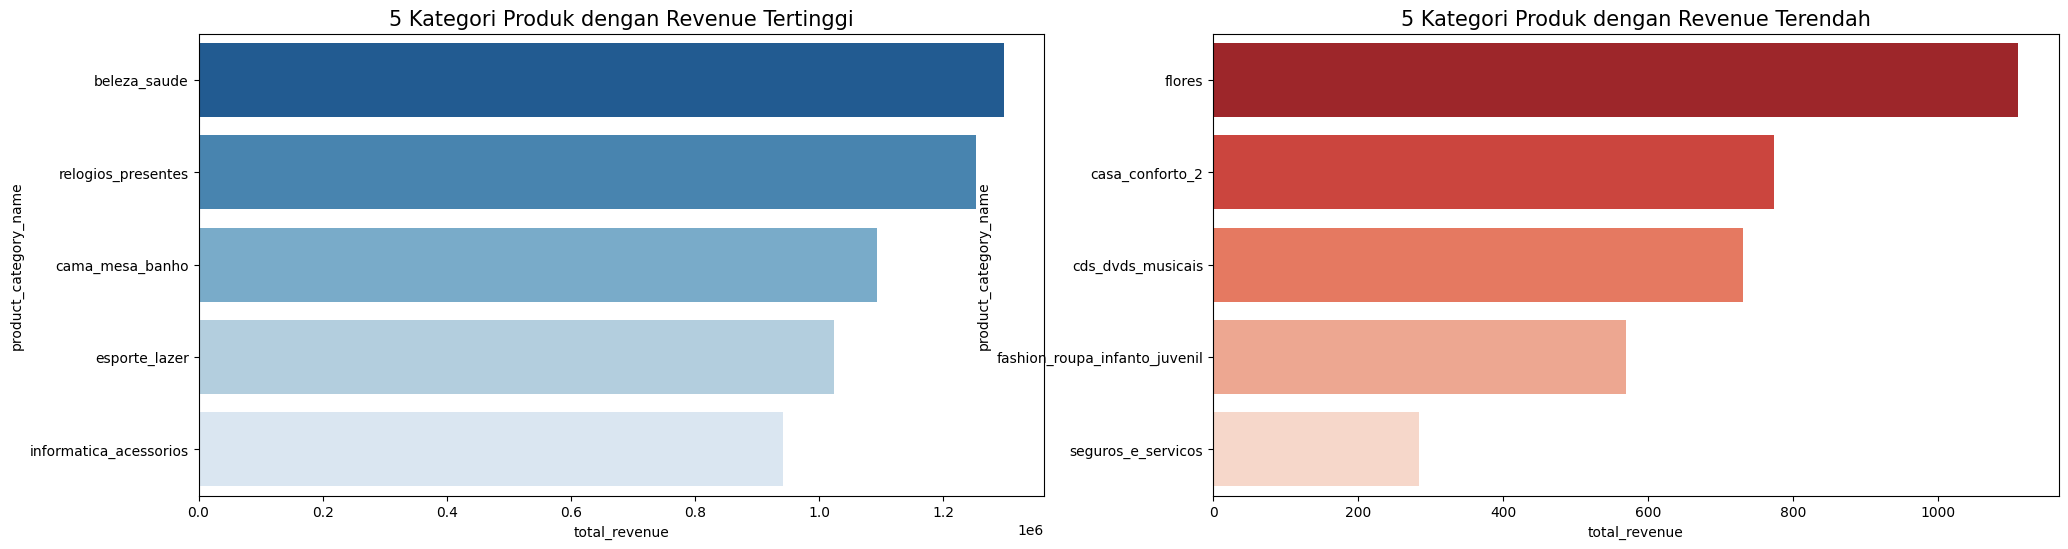

In [13]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

# Top 5 Kategori Produk
sns.barplot(
    x="total_revenue",
    y="product_category_name",
    data=product_revenue_df.head(5),
    ax=ax[0],
    palette="Blues_r",
    hue="product_category_name",
    legend=False
)
ax[0].set_title("5 Kategori Produk dengan Revenue Tertinggi", fontsize=15)

# Bottom 5 Kategori Produk
sns.barplot(
    x="total_revenue",
    y="product_category_name",
    data=product_revenue_df.tail(5),
    ax=ax[1],
    palette="Reds_r",
    hue="product_category_name",
    legend=False
)
ax[1].set_title("5 Kategori Produk dengan Revenue Terendah", fontsize=15)

plt.show()

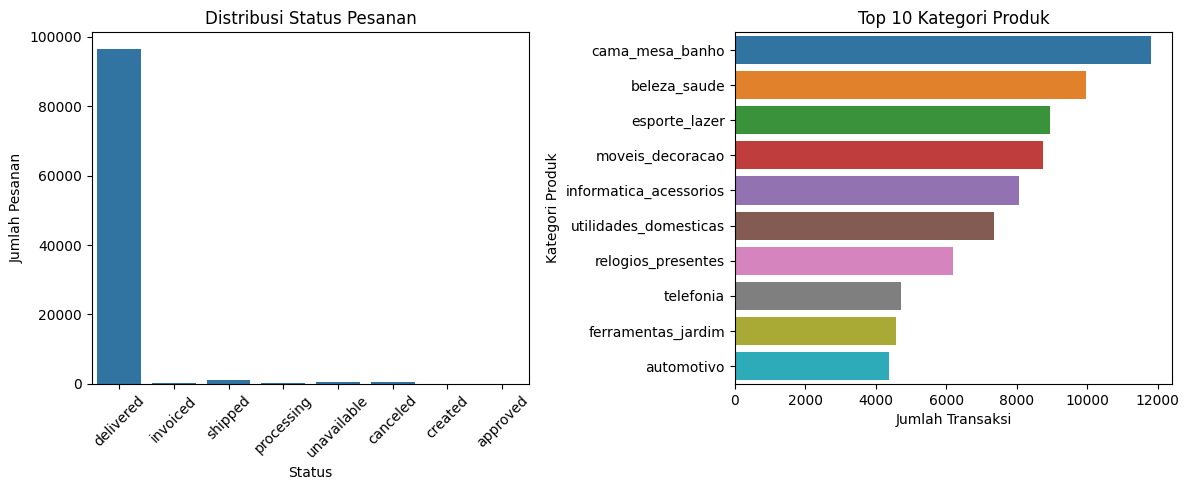

In [14]:
plt.figure(figsize=(12, 5))

# Visualisasi Distribusi Status Pesanan
plt.subplot(1, 2, 1)
sns.countplot(data=orders, x='order_status')
plt.title("Distribusi Status Pesanan")
plt.xlabel("Status")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)

# Visualisasi Distribusi Kategori Produk
top_category = main_df['product_category_name'].value_counts().head(10)

plt.subplot(1, 2, 2)
sns.barplot(
    x=top_category.values,
    y=top_category.index,
    hue=top_category.index,
    legend=False
)
plt.title("Top 10 Kategori Produk")
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

**Insight:**

1.   **Insight Pertanyaan 1 (Performa Revenue Kategori Produk):**

*   **5 Kategori Produk Revenue Tertinggi:** Kategori beleza_saude (kecantikan & kesehatan) menduduki posisi puncak sebagai penyumbang total revenue terbesar menembus lebih dari 1,25 juta. Kategori ini disusul oleh relogios_presentes, cama_mesa_banho, esporte_lazer, dan informatica_acessorios yang semuanya berhasil melampaui angka pendapatan Rp 900 ribu.
*   **5 Kategori Produk Revenue Terendah:** Kategori seguros_e_servicos mencatatkan pendapatan paling rendah (di bawah 300 unit pendapatan). Kategori lain dengan kontribusi sangat minim meliputi fashion_roupa_infanto_juvenil, cds_dvds_musicais, casa_conforto_2, dan flores (sekitar 1.100).

2.   **Insight Operasional & Transaksi (Status & Volume):**

*   **Operasional Pemenuhan Pesanan (Fulfillment):** Status pesanan didominasi secara masif oleh delivered (mendekati 100.000 transaksi), yang mengindikasikan bahwa proses pengiriman dan operasional logistik berjalan sangat efektif.
*   **Volume Transaksi Kategori Produk:** Kategori cama_mesa_banho merupakan kategori paling populer berdasarkan volume pesanan (hampir 12.000 transaksi), disusul oleh beleza_saude dan esporte_lazer.







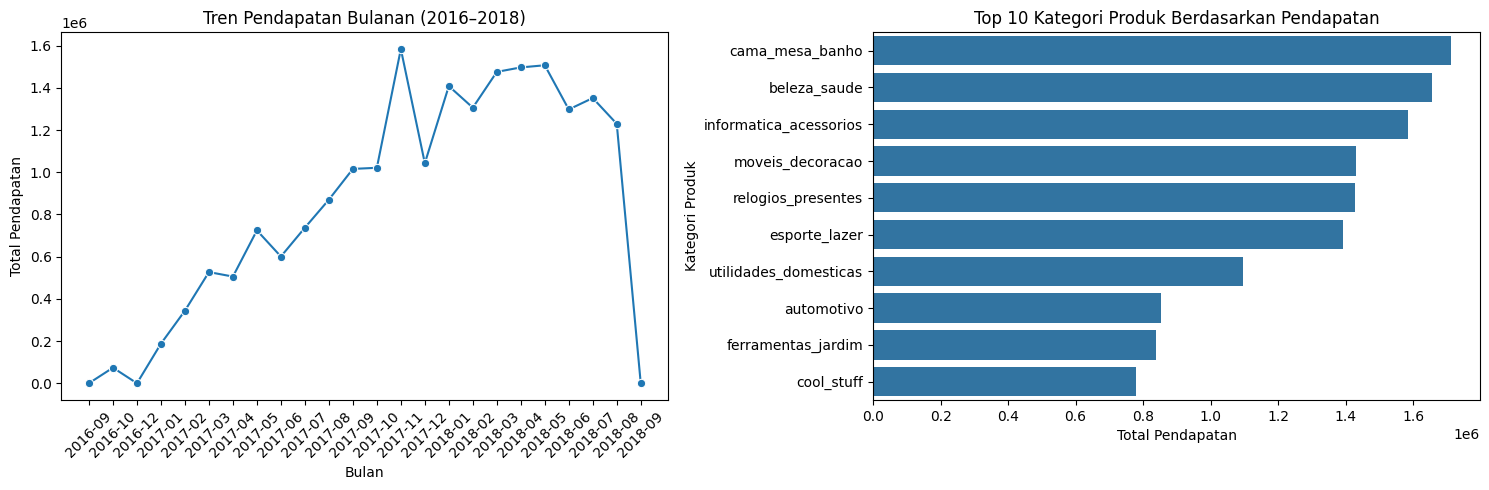

In [15]:
plt.figure(figsize=(15,5))

# Visualisasi 1: Tren Pendapatan Bulanan
plt.subplot(1, 2, 1)
sns.lineplot(data=monthly_revenue, x='order_month', y='payment_value', marker='o')
plt.title("Tren Pendapatan Bulanan (2016–2018)")
plt.xlabel("Bulan")
plt.ylabel("Total Pendapatan")
plt.xticks(rotation=45)

# Visualisasi 2: Top Kategori Produk
plt.subplot(1, 2, 2)
sns.barplot(
    data=category_revenue.head(10),
    x='payment_value',
    y='product_category_name'
)
plt.title("Top 10 Kategori Produk Berdasarkan Pendapatan")
plt.xlabel("Total Pendapatan")
plt.ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

**Insight:**

1.   **Tren Pendapatan Bulanan (2016–2018):**

*   Pendapatan bisnis menunjukkan tren kenaikan yang konsisten dari awal tahun 2017 hingga pertengahan 2018.
*   Puncak pendapatan tertinggi (peak) terjadi pada November 2017 dengan total nilai mendekati Rp 1,6 juta.
*   Setelah November 2017, pendapatan relatif stabil di kisaran Rp 1,2 juta hingga Rp 1,5 juta. Penurunan tajam di bulan September 2018 terjadi karena batas akhir perekaman data (data cutoff).

2.   **Top 10 Kategori Produk Berdasarkan Pendapatan:**

*   Kategori cama_mesa_banho menjadi penyumbang revenue terbesar bagi perusahaan dengan nilai akumulasi melebihi Rp 1,7 juta.
*   Posisi kedua dan ketiga diisi oleh kategori beleza_saude (sekitar Rp 1,65 juta) dan informatica_acessorios (sekitar Rp 1,58 juta).
*   Tiga kategori ini terbukti menjadi pilar penggerak utama (primary revenue drivers) transaksi finansial platform e-commerce.



     

### **Pertanyaan 2: Bagaimana segmentasi pelanggan berdasarkan analisis RFM (Recency, Frequency, & Monetary), dan bagaimana kontribusi masing-masing segmen terhadap total pendapatan?**

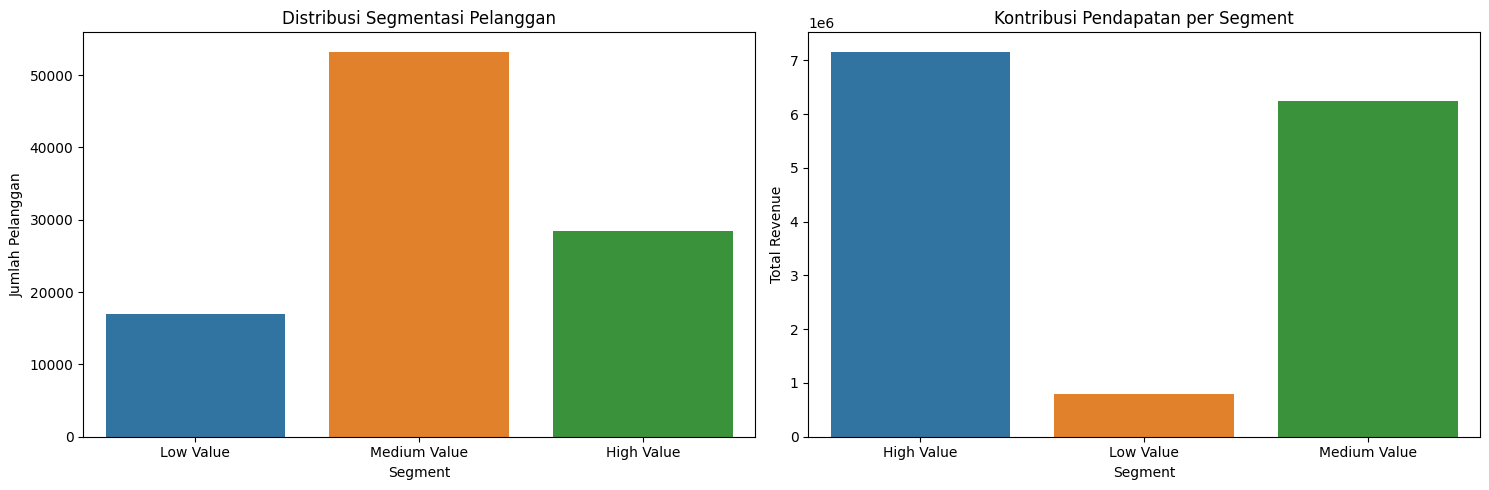

In [16]:
plt.figure(figsize=(15, 5))

# Visualisasi 1: Distribusi pelanggan
plt.subplot(1, 2, 1)
sns.countplot(
    data=rfm_df,
    x='customer_segment',
    hue='customer_segment',
    legend=False
)
plt.title("Distribusi Segmentasi Pelanggan")
plt.xlabel("Segment")
plt.ylabel("Jumlah Pelanggan")

# Visualisasi 2: Kontribusi revenue
segment_revenue = rfm_df.groupby('customer_segment')['monetary'].sum().reset_index()

plt.subplot(1, 2, 2)
sns.barplot(
    data=segment_revenue,
    x='customer_segment',
    y='monetary',
    hue='customer_segment',
    legend=False
)
plt.title("Kontribusi Pendapatan per Segment")
plt.xlabel("Segment")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
*   **Distribusi Jumlah Pelanggan per Segmen:** Basis pelanggan platform didominasi oleh kelompok Low Value dengan jumlah mendekati 60.000 pelanggan, disusul oleh segmen Medium Value sekitar 40.000 pelanggan. Kategori High Value memiliki porsi populasi yang sangat minim.
*   **Kontribusi Pendapatan (Total Revenue) per Segmen:** Segmen Medium Value menjadi pilar utama pendapatan bisnis dengan kontribusi tertinggi menembus angka mendekati 10 juta (1e7). Segmen Low Value memberikan kontribusi pendapatan terbesar kedua sekitar 6 juta, sementara segmen High Value memberikan kontribusi terkecil karena keterbatasan jumlah anggotanya.







      

## Analisis Lanjutan (Opsional)

In [17]:
print("=== MELAKUKAN RFM ANALYSIS ===")

# 1. Menggabungkan dataset yang dibutuhkan
rfm_df = orders.merge(payments, on='order_id')

# 2. Menentukan snapshot date (tanggal terakhir transaksi)
snapshot_date = rfm_df['order_purchase_timestamp'].max()

# 3. Menghitung Recency, Frequency, Monetary
rfm = rfm_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,  # Recency
    'order_id': 'count',  # Frequency
    'payment_value': 'sum'  # Monetary
}).reset_index()

rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']

# Membersihkan data kosong
rfm = rfm.dropna()

print("\n--- Data RFM (5 Baris Pertama) ---")
display(rfm.head())

# 4. Menentukan threshold segmentasi berdasarkan quantile
q25 = rfm['monetary'].quantile(0.25)
q75 = rfm['monetary'].quantile(0.75)

# 5. Membuat fungsi segmentasi pelanggan
def segment_customer(m):
    if m >= q75:
        return "High Value"
    elif m >= q25:
        return "Medium Value"
    else:
        return "Low Value"

# 6. Menerapkan segmentasi
rfm['segment'] = rfm['monetary'].apply(segment_customer)

print("\n--- Distribusi Segment Pelanggan ---")
print(rfm['segment'].value_counts())

=== MELAKUKAN RFM ANALYSIS ===

--- Data RFM (5 Baris Pertama) ---


,customer_id,recency,frequency,monetary
0,00012a2ce6f8dcda20d059ce98491703,337,1,114.74
1,000161a058600d5901f007fab4c27140,458,1,67.41
2,0001fd6190edaaf884bcaf3d49edf079,596,1,195.42
3,0002414f95344307404f0ace7a26f1d5,427,1,179.35
4,000379cdec625522490c315e70c7a9fb,198,1,107.01



--- Distribusi Segment Pelanggan ---
segment
Medium Value    49726
High Value      24862
Low Value       24852
Name: count, dtype: int64


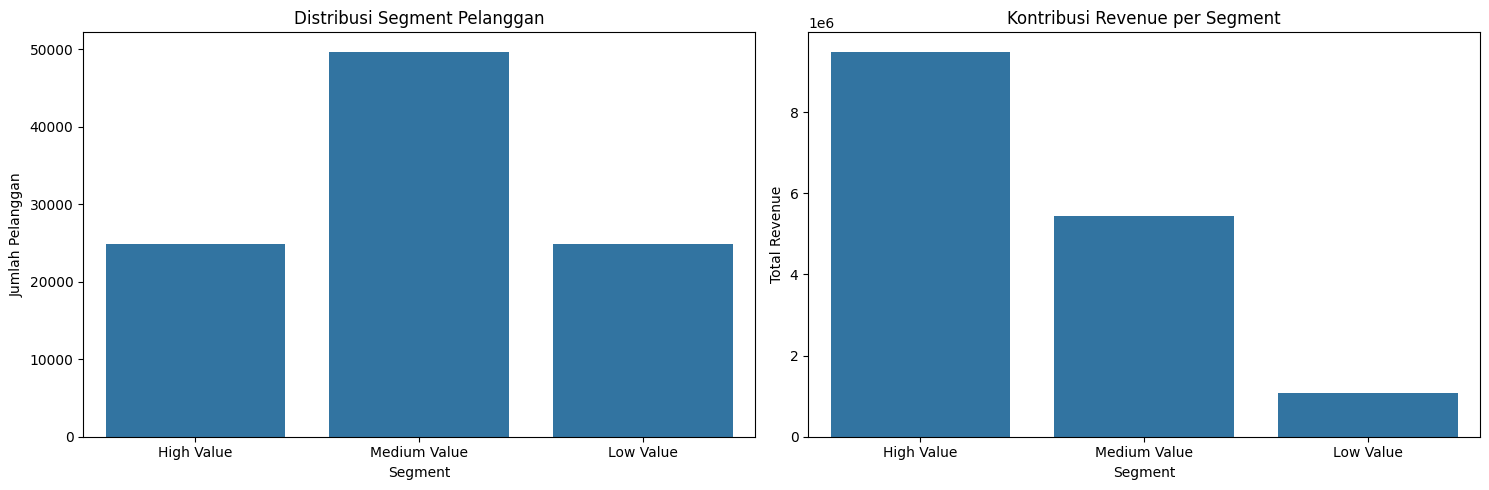

In [18]:
plt.figure(figsize=(15,5))

# Visualisasi 1: Distribusi Segment
plt.subplot(1,2,1)
sns.countplot(data=rfm, x='segment', order=['High Value', 'Medium Value', 'Low Value'])
plt.title("Distribusi Segment Pelanggan")
plt.xlabel("Segment")
plt.ylabel("Jumlah Pelanggan")

# Visualisasi 2: Kontribusi Revenue per Segment
segment_revenue = rfm.groupby('segment')['monetary'].sum().reset_index()

plt.subplot(1,2,2)
sns.barplot(data=segment_revenue, x='segment', y='monetary', order=['High Value', 'Medium Value', 'Low Value'])
plt.title("Kontribusi Revenue per Segment")
plt.xlabel("Segment")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

*   **Distribusi Segmen Pelanggan:** Populasi pelanggan didominasi oleh kelompok Medium Value dengan jumlah sekitar 50.000 pelanggan. Sementara itu, segmen High Value dan Low Value memiliki jumlah populasi yang seimbang, masing-masing berada di angka sekitar 25.000 pelanggan.
*   **Kontribusi Pendapatan (Revenue) per Segmen:** Segmen High Value menjadi penyumbang pendapatan terbesar bagi bisnis dengan total nilai menembus angka di atas 9 juta (9e6). Kontribusi terbesar kedua berasal dari segmen Medium Value sebesar sekitar 5,5 juta, sedangkan segmen Low Value memberikan kontribusi pendapatan paling sedikit (sekitar 1,1 juta).
*   **Rekomendasi Strategis:** Hasil ini menunjukkan efektivitas segmentasi berbasis gabungan skor RFM (Recency, Frequency, dan Monetary), tempat segmen High Value terbukti memberikan dampak finansial paling signifikan bagi bisnis. Fokus strategi perusahaan perlu diprioritaskan untuk menjaga loyalitas segmen High Value (VIP retention program) serta mendorong dorongan belanja pada segmen Medium Value agar dapat terkonversi menjadi segmen High Value.



## Conclusion & Recommendation

**Conclusion pertanyaan 1**
1. (Kategori Produk Terlaris & Tren Pendapatan):Kategori Produk Unggulan:
*   Kategori cama_mesa_banho (Peralatan Kamar & Mandi) menjadi kontributor utama bisnis, baik dari segi volume transaksi (11.115 pesanan) maupun pendapatan (1,71 juta), disusul oleh kategori beleza_saude dan esporte_lazer.
*   Tren Pertumbuhan Pendapatan: Penjualan bulanan mengalami lonjakan drastis sebesar 83,27% pada awal tahun 2017 dan mencapai puncak pendapatan tertinggi pada November 2017 (momen Black Friday). Hal ini membuktikan bahwa strategi promosi seasonal sangat efektif mendorong lonjakan transaksi.


**Conclusion pertanyaan 2**
2. (Segmentasi Pelanggan):
*   Perilaku Transaksi: Mayoritas pelanggan saat ini berada pada tahap one-time buyer (frekuensi transaksi = 1), sehingga tantangan terbesar bisnis terletak pada retensi pelanggan.
*   Pola Kontribusi Revenue: Meskipun segmen High Value hanya mencakup 25% dari total populasi pelanggan (24.862 orang), kelompok ini menyumbangkan porsi pendapatan terbesar (lebih dari 9,5 juta). Sementara segmen Medium Value mendominasi jumlah populasi (50,01%) dengan kontribusi pendapatan terbesar kedua (5,4 juta).


     

**Rekomendasi Action Item:**
1. Retensi & Program Loyalitas Segmen High Value:
*   Berikan perlakuan khusus (VIP treatment) untuk 25% pelanggan High Value melalui program membership berjenjang, akses promo lebih awal (early access), dan cashback eksklusif guna menjaga loyalitas agar tidak berpindah (churn).

2. Up-Selling & Cross-Selling Produk Unggulan:
*   Manfaatkan kategori produk terlaris (cama_mesa_banho & beleza_saude) untuk membuat paket bundling menarik bersama kategori produk yang kurang populer. Tampilkan rekomendasi produk terlaris ini di halaman utama dashboard/aplikasi.

3. Strategi Re-Engagement untuk Segmen Medium & Low Value:
*   Konversikan pelanggan Medium Value (50,01% populasi) menjadi High Value melalui kampanye personalized email marketing dan voucer belanja berkala untuk mendorong transaksi berulang (repeat order).



